In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

In [2]:
categories = ["rec.sport.baseball", "rec.sport.hockey", "sci.space", "sci.med"]

In [3]:
train_data = fetch_20newsgroups(subset="train", categories=categories, remove=("headers", "footers", "quotes"))
test_data = fetch_20newsgroups(subset="test", categories=categories, remove=("headers", "footers", "quotes"))
X_train = train_data.data
y_train = train_data.target
X_test = test_data.data
y_test = test_data.target

In [4]:
vectorizer = TfidfVectorizer(stop_words="english", max_features=10000)
X_train = vectorizer.fit_transform(X_train)
X_test = vectorizer.transform(X_test)

In [5]:
model = MultinomialNB(alpha=0.1)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=train_data.target_names))

Accuracy: 0.8883984867591425

Classification Report:
                    precision    recall  f1-score   support

rec.sport.baseball       0.93      0.86      0.89       397
  rec.sport.hockey       0.83      0.93      0.88       399
           sci.med       0.91      0.87      0.89       396
         sci.space       0.90      0.89      0.89       394

          accuracy                           0.89      1586
         macro avg       0.89      0.89      0.89      1586
      weighted avg       0.89      0.89      0.89      1586



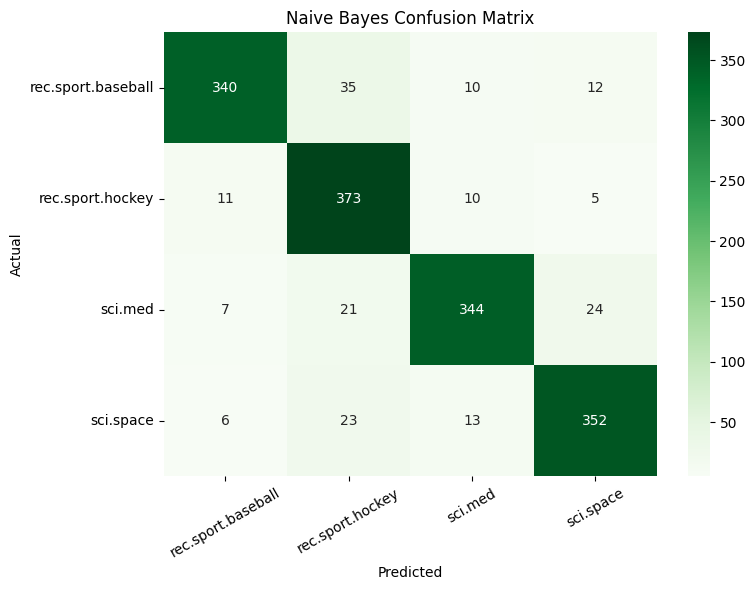

In [6]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=train_data.target_names, yticklabels=train_data.target_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Naive Bayes Confusion Matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()